In [1]:
import numpy as np
import pandas as pd

In [2]:
df_train = pd.read_csv('./data/traj_data_train.csv')
df_val = pd.read_csv('./data/traj_data_val.csv')
df_test = pd.read_csv('./data/traj_data_test.csv')

In [3]:
df_train

,traj,step,m:icustayid,r:reward,a:action,a:vaso,a:iv,s:state
0,1,0,200003.0,0.0,5,0,1,550
1,1,1,200003.0,0.0,5,0,1,312
2,1,2,200003.0,0.0,5,0,1,312
3,1,3,200003.0,0.0,5,0,1,312
4,1,4,200003.0,0.0,5,0,1,551
...,...,...,...,...,...,...,...,...
179446,19625,15,299992.0,0.0,8,3,1,131
179447,19625,16,299992.0,0.0,8,3,1,603
179448,19625,17,299992.0,0.0,7,2,1,265
179449,19625,18,299992.0,0.0,7,2,1,265


In [13]:
df_i = df_train[df_train['traj'] == 20].copy()

In [14]:
df_i[['step', 's:state', 'a:action']]

,step,s:state,a:action
179,0,432,15
180,1,577,20
181,2,405,15
182,3,428,5
183,4,468,5
184,5,54,5
185,6,705,5
186,7,82,5
187,8,616,5
188,9,487,0


In [19]:
df_i['a:next_action'] = -1
df_i['a:next_action'] = df_i['a:action'].shift(-1)

In [20]:
df_i

,traj,step,m:icustayid,r:reward,a:action,a:vaso,a:iv,s:state,a:next_action
179,20,0,200099.0,0.0,15,0,3,432,20.0
180,20,1,200099.0,0.0,20,0,4,577,15.0
181,20,2,200099.0,0.0,15,0,3,405,5.0
182,20,3,200099.0,0.0,5,0,1,428,5.0
183,20,4,200099.0,0.0,5,0,1,468,5.0
184,20,5,200099.0,0.0,5,0,1,54,5.0
185,20,6,200099.0,0.0,5,0,1,705,5.0
186,20,7,200099.0,0.0,5,0,1,82,5.0
187,20,8,200099.0,0.0,5,0,1,616,0.0
188,20,9,200099.0,0.0,0,0,0,487,0.0


In [ ]:
# How often are a_t vs a_{t+1} different? If they are always the same RL is irrelevant, 

In [ ]:
# How does it affect transition matrix and behavior policy? 

In [ ]:
Ps = np.load(project_dir + 'data/env_model/P.npz')
R = np.load(project_dir + 'data/env_model/R.npy')
P_orig = Ps['P_orig']
P_dropped = Ps['P_dropped']
P_shifted = Ps['P_shifted']

In [ ]:
P_orig.shape, R.shape

((752, 25, 752), (752, 25, 752))

In [ ]:
P = P_orig
SA_mask = SA_mask_orig

In [ ]:
Vs = []
V = np.zeros(nS_total)
for i in tqdm(itertools.count()):
    V_new = V.copy()
    for s in range(nS):
        ## V[s] = max {a} sum {s', r} P[s', r | s, a] * (r + gamma * V[s'])
        Q_s = np.zeros((nA))
        for a in range(nA):
            Q_s[a] = sum(P[s, a, s_] * (R[s, a, s_] + gamma * V[s_]) for s_ in range(nS_total) if P[s , a, s_] > 0)
        Q_s[~SA_mask[s]] = np.nan
        new_v = np.nanmax(Q_s)
        V_new[s] = new_v
    Vs.append(V_new)
    V = V_new
    if np.isclose(np.linalg.norm(V_new - V), 0.3):
        break

34it [01:39,  2.91s/it]


KeyboardInterrupt: 

In [ ]:
Vs = []
V = np.zeros(nS)
Vs.append(V.copy())
for i in tqdm(itertools.count()):
    V_new = V.copy()
    for s in range(nS):
        ## V[s] = max {a} sum {s', r} P[s', r | s, a] * (r + gamma * V[s'])
        Q_s = np.zeros((nA))
        for a in range(nA):
            Q_s[a] = sum(p * (r + (0 if done else gamma * V[s_])) for p, s_, r, done in gymP[s][a])
        Q_s[~SA_mask[s]] = np.nan
        new_v = np.nanmax(Q_s)
        V_new[s] = new_v
    if np.isclose(np.linalg.norm(V_new - V), 1e-10):
        break
    V = V_new
    Vs.append(V_new)

130it [00:06, 18.94it/s]


## Per Decision DR

In [ ]:
π_e = π_b.copy()

In [ ]:
V_DR, DR_stats = perdecision_DR_recursive(trajectories_test, π_e, π_b, np.zeros_like(Q_star), np.zeros_like(V_star), γ)
print(V_DR)

0.8358565737051793


In [ ]:
V_DR, DR_stats = perdecision_DR(trajectories_test, π_e, π_b, np.zeros_like(Q_star), np.zeros_like(V_star), γ)
print(V_DR)

0.8358565737051793


In [ ]:
# Soften policy to create evaluation policy
epsilon = 0.05
π_e = (1 - epsilon) * π_star + epsilon * π_b

In [ ]:
V_DR, DR_stats = perdecision_DR_recursive(trajectories_test, π_e, π_b, Q_star, V_star, γ, clip_value=(-1, 1))
print(V_DR)

0.8651201675314636


In [ ]:
V_DR, DR_stats = perdecision_DR(trajectories_test, π_e, π_b, Q_star, V_star, γ, clip_value=(-1, 1))
print(V_DR)

0.8651201675314636


In [ ]:
V_WDR, WDR_stats = perdecision_WDR(trajectories_test, π_e, π_b, Q_star, V_star, γ, clip_value=(-1, 1))
print(V_WDR)

0.9278682423038559


In [ ]:
V_DR_b = []
for i in tqdm(range(1000)):
    G_list_boot = resample(DR_stats['v_list'], replace=True, random_state=i)
    V_DR_boot = np.sum(G_list_boot) / len(trajectories_test)
    V_DR_b.append(V_DR_boot)
V_DR_b = np.array(V_DR_b)
print(V_DR_b.mean(), V_DR_b.std())
print(np.median(V_DR_b))
print(np.percentile(V_DR_b, 2.5), np.percentile(V_DR_b, 97.5))

100%|███████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2250.48it/s]

0.864864199910016 0.006790935566559398
0.8649143341926573
0.8512078865807411 0.8777677924942787


In [ ]:
V_WDR_b = []
for i in tqdm(range(1000)):
    G_list_boot = resample(WDR_stats['v_list'], replace=True, random_state=i)
    V_WDR_boot = np.sum(G_list_boot) / len(trajectories_test)
    V_WDR_b.append(V_WDR_boot)
V_WDR_b = np.array(V_WDR_b)
print(V_WDR_b.mean(), V_WDR_b.std())
print(np.median(V_WDR_b))
print(np.percentile(V_WDR_b, 2.5), np.percentile(V_WDR_b, 97.5))

100%|███████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 2247.21it/s]

0.9278940110888694 0.002722466183798713
0.9280119327473193
0.922444100442341 0.9328883216849122


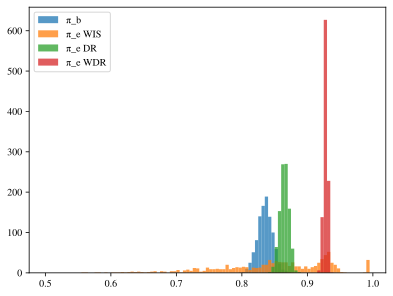

In [ ]:
plt.hist(V_IS_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_b')
plt.hist(V_WIS_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_e WIS')
plt.hist(V_DR_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_e DR')
plt.hist(V_WDR_b, alpha=0.75, bins=np.arange(0.5, 1.0, 0.005), label='π_e WDR')
plt.legend()
plt.show()